### Import libraries

In [1]:
library(ggplot2)
library(scales)
library(gtable)
library(grid)
library(cowplot)
library(ggrepel)
library(gggenes)
options(repr.plot.width = 50, repr.plot.height = 35)

Warning message:
“package ‘ggplot2’ was built under R version 4.4.3”
Warning message:
“package ‘scales’ was built under R version 4.4.3”
Warning message:
“package ‘gtable’ was built under R version 4.4.3”
Warning message:
“package ‘cowplot’ was built under R version 4.4.3”
Warning message:
“package ‘ggrepel’ was built under R version 4.4.3”
Warning message:
“package ‘gggenes’ was built under R version 4.4.3”


In [2]:
df = read.table("/home/lknq/notebook/GALC_plot/analysis.txt", header = T, sep = "\t")
# head(df, 2)
df <- df[order(df$Start), ]
# print(df)

In [3]:
gene_start = 88304163

df$pos = df$Start - gene_start + 1

df$point_size <- scales::rescale(
    df$Total,
    to = c(20, 40)
)
print(df)


     Chr    Start      End                                      Clinvar
1  chr14 88401213 88401213                                       Benign
2  chr14 88401219 88401219                    Not available in database
3  chr14 88401222 88401222 Conflicting classifications of pathogenicity
4  chr14 88406259 88406259                 Pathogenic/Likely pathogenic
5  chr14 88406315 88406315                                Likely benign
6  chr14 88407757 88407757                       Uncertain significance
7  chr14 88407795 88407795                       Uncertain significance
8  chr14 88407875 88407875                                       Benign
9  chr14 88407888 88407888                                       Benign
10 chr14 88411947 88411947                                       Benign
11 chr14 88411951 88411951                    Not available in database
12 chr14 88411975 88411975                 Pathogenic/Likely pathogenic
13 chr14 88411994 88411994 Conflicting classifications of pathog

# Main chart

Warning message:
“The `size` argument of `element_rect()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.”
Warning message in geom_segment(aes(x = 88401213, xend = 88459795, y = -85, yend = -85), :
“All aesthetics have length 1, but the data has 28 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”
Warning message in geom_text(aes(x = (88399358 + 88459526)/2, y = -200, label = "GALC exons"), :
“All aesthetics have length 1, but the data has 28 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”


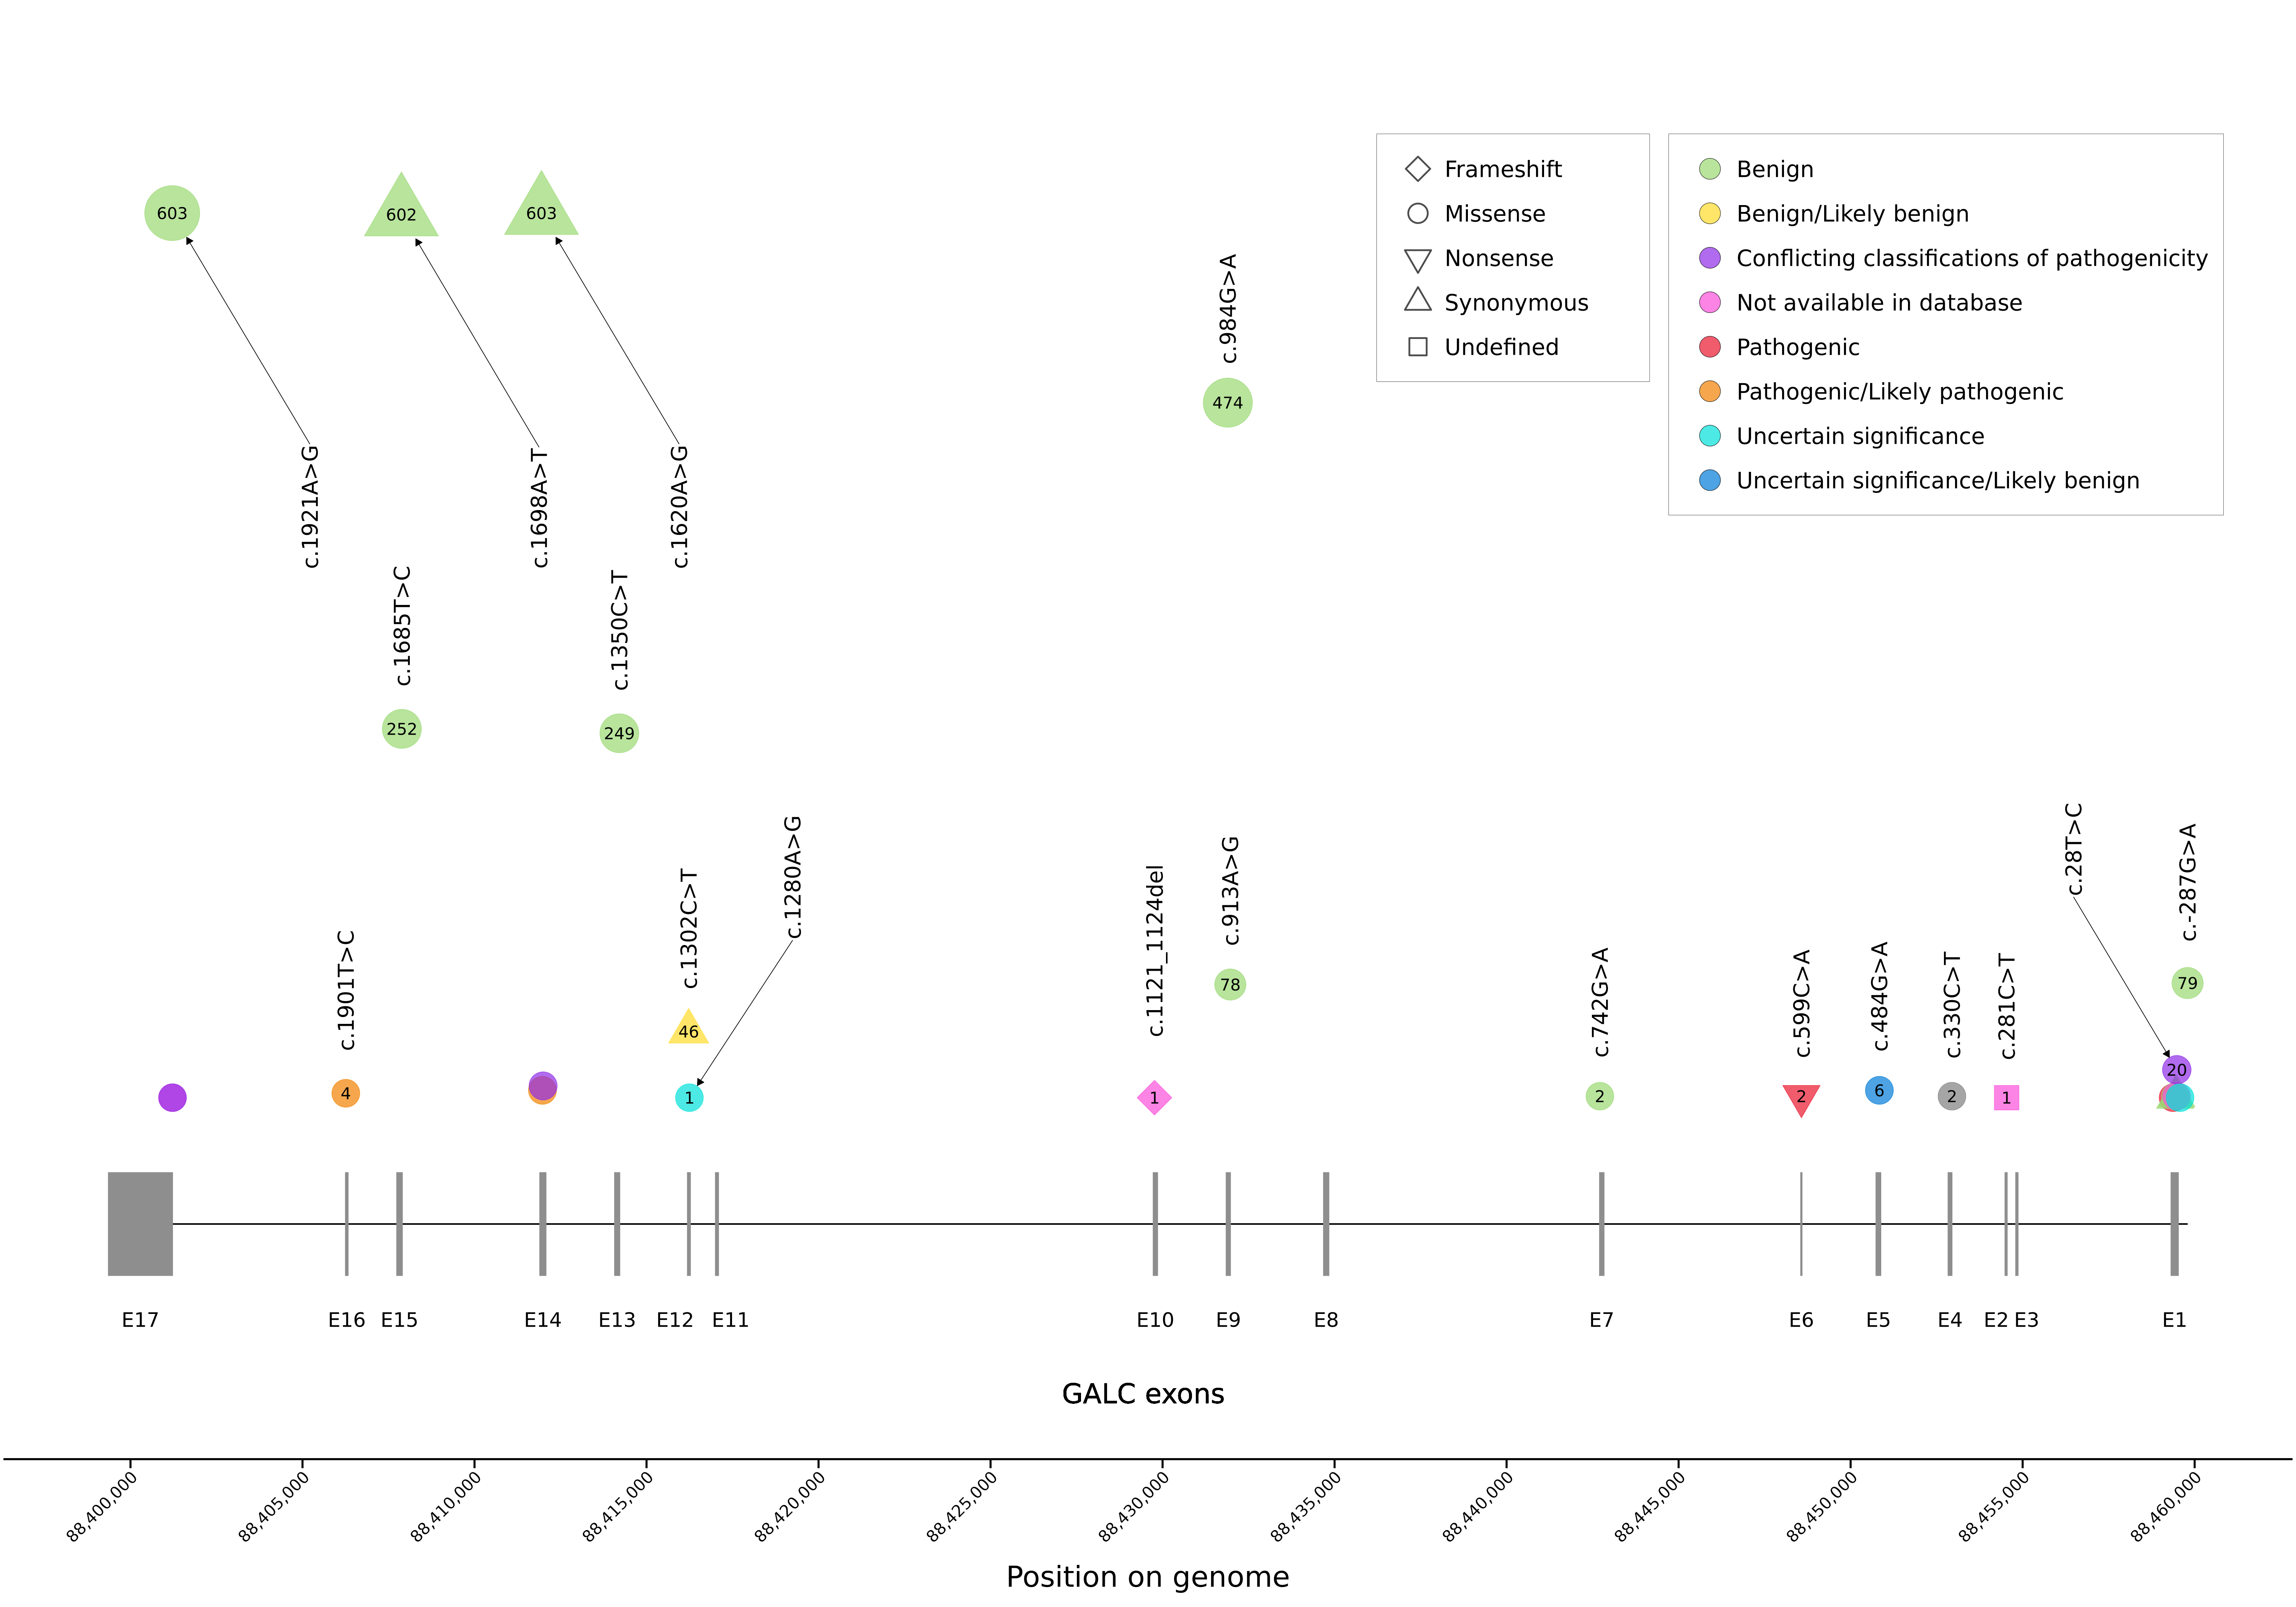

In [4]:

# 23     1 144401
# 24     2 144409
# 25     1 146608
# 26     6 146674

exons <- data.frame(
  exon = paste("E",1:17 , sep = ""),
  start = c(88459314, 88454799, 88454488, 88452833, 88450738, 88448549, 88442702, 88434679, 88431849, 88429728, 88417003, 88416189, 88414072, 88411897, 88407739, 88406249, 88399358),
  end   = c(88459526, 88454867, 88454551, 88452946, 88450877, 88448587, 88442832, 88434834, 88431973, 88429855, 88417092, 88416275, 88414222, 88412077, 88407902, 88406325, 88401222),
  y = 1
)

main_chart = ggplot(            #Plot
    data=subset(df, !(pos %in% c(102153, 103595, 103633, 112866, 112920, 107789, 144401, 146608))),
    aes(x=Start, y=Total)
) + 
ylab(
    "The number of variants"
) + 
xlab(
    "Position on genome"
) + 
scale_x_continuous(
    labels=comma, 
    breaks = scales::pretty_breaks(n=10), 
    limits = c(88399358, max(df$Start))
) + 
scale_y_continuous(
    limits=c(-200, 700)
) + 
geom_point(
    aes(
        shape = Functional_consequence,
        color = Clinvar,
        fill  = Clinvar,
        size  = point_size
    ),
    alpha = 0.7
) + 
scale_size_identity(

) + 
geom_text(
    data = subset(df, Total %in% c(603, 602, 252, 249, 46, 474, 78, 79) | Start %in% c(88429765, 88442712, 88452945, 88454535) | pos %in% c(102097, 112085, 144409, 146674, 155319)),
    aes(label = round(Total, 1)),
    color = "black",
    size = 9
) + theme_cowplot(
) + 
theme(
    axis.line.y = element_blank(),
    axis.text.y = element_blank(),
    axis.ticks.y = element_blank(),
    axis.title.y = element_blank(),
    
    axis.text.x = element_text(
        size = 25,
        angle = 45, 
        hjust = 1
    ),
    axis.ticks.length = unit(5, "mm"),
    axis.line = element_line(
      linewidth = 1.5
    ),
    axis.ticks = element_line(
      linewidth = 1.5
    ),
    axis.title.x = element_text(
        # face = "bold",
        size = 45,
        margin = margin(t = 45, b = 15)
    ),
    legend.box = "horizontal",
    legend.position = c(0.6, 0.78),
    legend.title = element_blank(),
    legend.background = element_rect(
        colour = "black",
        fill = "white",
        size=0.2
    ),
    # legend.background = element_rect(
    #     fill = NA,
    #     color = NA
    # ),
    legend.text = element_text(size = 35),
    legend.key.size = unit(70, "pt"),
    legend.margin = margin(20, 120, 20, 30),
    legend.spacing.x = unit(30, "pt")
) + guides(
        shape = guide_legend(
        order = 1,
        override.aes = list(size = 13, stroke = 2)
    ),
        color = "none",
        fill  = guide_legend(
            order = 2, 
            override.aes = list(shape = 21, size = 15)
    )
) + scale_fill_manual(
    values = c(
        "Pathogenic"                                   = "#e9162d",
        "Pathogenic/Likely pathogenic"                 = "#f28100",
        "Benign"                                       = "#9AD872",#9AD872
        "Benign/Likely benign"                         = "#ffdb28",
        "Uncertain significance"                       = "#00e1da",
        "Uncertain significance/Likely benign"         = "#007bd8",
        "Conflicting classifications of pathogenicity" = "#8f2be7",
        "Not available in database"                    = "#fb4fd9"
    ),
    na.value = "grey50"
) + 
scale_color_manual(
    values = c(
        "Pathogenic"                                   = "#e9162d",
        "Pathogenic/Likely pathogenic"                 = "#f28200",
        "Benign"                                       = "#9AD872",#9AD872
        "Benign/Likely benign"                         = "#ffdb28",
        "Uncertain significance"                       = "#00e1da",
        "Uncertain significance/Likely benign"         = "#007bd8",
        "Conflicting classifications of pathogenicity" = "#8f2be7",
        "Not available in database"                    = "#fb4fd9"
    ),
    na.value = "grey50"
) + scale_shape_manual(values = c(
        "Missense"   = 21,
        "Synonymous" = 24,
        "Nonsense"   = 25,
        "Frameshift" = 23,
        "Undefined"  = 22
    )
) + geom_text_repel( # 16     1 112085
    data = subset(df, pos %in% c(112085)),
    box.padding = 5,
    aes(label = Name),
    angle = 90,
    direction="both",
    nudge_x = 3000,
    nudge_y = 150,
    segment.color = "black",
    min.segment.length = 0,
    size=12,
    point.padding = 1.5,
    # segment.curvature = -1e-20,
    arrow = arrow(
        length = unit(0.4, "cm"),
        type = "closed"
    ),
    segment.size=0.5,
    segment.angle = 45,
) + geom_text_repel( # # 34    20 155319   9.003292
    data = subset(df, pos %in% c(155319)),
    box.padding = 5,
    aes(label = Name),
    angle = 90,
    direction="both",
    nudge_x = -3000,
    nudge_y = 150,
    segment.color = "black",
    min.segment.length = 0,
    size=12,
    point.padding = 1.5,
    # segment.curvature = -1e-20,
    arrow = arrow(
        length = unit(0.4, "cm"),
        type = "closed"
    ),
    segment.size=0.5,
    segment.angle = 45,
) + geom_text_repel( # 603  97051   40.00000
    data = subset(df, pos %in% c(97051)),
    box.padding = 5,
    aes(label = Name),
    angle = 90,
    direction="both",
    nudge_x = 4000,
    nudge_y = -200,
    segment.color = "black",
    min.segment.length = 0,
    size=12,
    point.padding = 3,
    # segment.curvature = -1e-20,
    arrow = arrow(
        length = unit(0.4, "cm"),
        type = "closed"
    ),
    segment.size=0.5,
    segment.angle = 45,
) + geom_text_repel( # 8    602 103713   39.96678
    data = subset(df, pos %in% c(103713)),
    box.padding = 5,
    aes(label = Name),
    angle = 90,
    direction="both",
    nudge_x = 4000,
    nudge_y = -200,
    segment.color = "black",
    min.segment.length = 0,
    size=12,
    point.padding = 3,
    # segment.curvature = -1e-20,
    arrow = arrow(
        length = unit(0.4, "cm"),
        type = "closed"
    ),
    segment.size=0.5,
    segment.angle = 45,
) + geom_text_repel( # 10   603 107785   40.00000
    data = subset(df, pos %in% c(107785)),
    box.padding = 5,
    aes(label = Name),
    angle = 90,
    direction="both",
    nudge_x = 4000,
    nudge_y = -200,
    segment.color = "black",
    min.segment.length = 0,
    size=12,
    point.padding = 3,
    # segment.curvature = -1e-20,
    arrow = arrow(
        length = unit(0.4, "cm"),
        type = "closed"
    ),
    segment.size=0.5,
    segment.angle = 45,
)

main_chart = main_chart + geom_text(
    data = subset(df, Total %in% c(252, 249, 46, 474, 78, 79) | Start %in% c(88429765, 88442712, 88452945, 88454535) | pos %in% c(102097, 144409, 146674)),
    aes(label = Name),
    vjust = 0.5,
    hjust = -0.35,
    size = 12,
    angle = 90
) + geom_segment(
    aes(x = 88401213, xend = 88459795,
        y = -85, yend = -85),
    linewidth = 1
) + geom_rect(
    data = exons,
    inherit.aes = FALSE,
    aes(
      xmin = pmin(start, end),
      xmax = pmax(start, end),
      ymin = -120,
      ymax = -50
    ),
    fill = "#8e8e8e",
    color = "#8e8e8e"
) + 
geom_text(
    data = subset(exons, !exon %in% c("E2", "E3", "E11", "E12")),
    aes(
      x = (start + end)/2,
      y = -150,
      label = exon
    ),
    size = 11
) + 
geom_text(
    data = subset(exons, exon %in% c("E2")),
    aes(
      x = (start + end)/2 - 600,
      y = -150,
      label = exon
    ),
    size = 11
) + 
geom_text(
    data = subset(exons, exon %in% c("E3")),
    aes(
      x = (start + end)/2 + 600,
      y = -150,
      label = exon
    ),
    size = 11
) + 
geom_text(
    data = subset(exons, exon %in% c("E12")),
    aes(
      x = (start + end)/2 - 400,
      y = -150,
      label = exon
    ),
    size = 11
) + 
geom_text(
    data = subset(exons, exon %in% c("E11")),
    aes(
      x = (start + end)/2 + 400,
      y = -150,
      label = exon
    ),
    size = 11
) + 
geom_text(
    aes(
        x = (88399358 + 88459526)/2,
        y = -200,
        label = "GALC exons"
    ),
    size = 15,
)

main_chart


# Subchart 1

In [5]:
subchart_1 = ggplot(                    # Plot
    data= subset(df, Total < 2), 
    aes(x = pos, y = Total)
    ) + coord_cartesian(
        xlim = c(97057, 97060), 
        ylim = c(0.95, 1.5)
    ) + 
    geom_point(
        aes(
            shape = Functional_consequence,
            color = Clinvar,
            fill  = Clinvar,
            size  = point_size
        ),
        alpha = 0.7
    ) + 
    scale_size_identity(   
            
    ) + geom_text(
        aes(label = round(Total, 1)),
        color = "black",
        size = 9
    ) + 
    theme_classic(

    ) +
    theme(
        axis.line.y = element_blank(),
        axis.text.y = element_blank(),
        axis.ticks.y = element_blank(),
        axis.title.y = element_blank(),
        
        axis.line.x = element_blank(),
        axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        axis.title.x = element_blank(),
        legend.position = "none"
    ) + scale_fill_manual(
    values = c(
        "Pathogenic"                                   = "#e9162d",
        "Pathogenic/Likely pathogenic"                 = "#f28200",
        "Benign"                                       = "#9AD872",#9AD872
        "Benign/Likely benign"                         = "#ffdb28",
        "Uncertain significance"                       = "#00e1da",
        "Uncertain significance/Likely benign"         = "#007bd8",
        "Conflicting classifications of pathogenicity" = "#8f2be7",
        "Not available in database"                    = "#fb4fd9"
    ),
    na.value = "grey50"
) + 
scale_color_manual(
    values = c(
        "Pathogenic"                                   = "#e9162d",
        "Pathogenic/Likely pathogenic"                 = "#f28200",
        "Benign"                                       = "#9AD872",#9AD872
        "Benign/Likely benign"                         = "#ffdb28",
        "Uncertain significance"                       = "#00e1da",
        "Uncertain significance/Likely benign"         = "#007bd8",
        "Conflicting classifications of pathogenicity" = "#8f2be7",
        "Not available in database"                    = "#fb4fd9"
    ),
    na.value = "grey50"
) + scale_shape_manual(values = c(
        "Missense"   = 21,
        "Synonymous" = 24,
        "Nonsense"   = 25,
        "Frameshift" = 23,
        "Undefined"  = 22
    )
)

subchart_1 = subchart_1 + geom_text(
    data = df,
    aes(label = Name),
    vjust = 0.5,
    hjust = -0.35,
    size = 12,
    angle = 90
)

# subchart_1

# Subchart 2

In [6]:

# 6      1 103595
# 7      1 103633

subchart_2 = ggplot(                    # Plot
    data= subset(df, Total < 2), 
    aes(x = pos, y = Total)
    ) + coord_cartesian(
        xlim = c(103595, 103633), 
        ylim = c(0.95, 1.5)
    ) + geom_point(
        pch=21, 
        aes(
            color = Functional_consequence,
            fill = Functional_consequence,
            size = point_size
        ),
        alpha = 0.9,
    ) + 
    scale_size_identity(   
            
    ) + geom_text(
        aes(label = round(Total, 1)),
        color = "black",
        size = 5
    ) + 
    theme_classic(

    ) +
    theme(
        axis.line.y = element_blank(),
        axis.text.y = element_blank(),
        axis.ticks.y = element_blank(),
        axis.title.y = element_blank(),
        
        axis.line.x = element_blank(),
        axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        axis.title.x = element_blank(),
        legend.position = "none"
    ) + 
    scale_fill_manual(
        values = c(
            "nonsense" = "#ef736c",
            "missense" = "#9fc7fb",
            "synonymous" = "#ffebb2",
            "frameshift" = "#a1c089"
        ),
        na.value = "grey50"
    ) + 
    scale_color_manual(
        values = c(
            "missense"   = "#4575b4",
            "synonymous" = "#ffd767",
            "nonsense"   = "#d51a10"
        ),
        na.value = "grey50"
    ) + geom_text(
    data = df,
    aes(label = Name),
    vjust = 0.5,
    hjust = -0.35,
    size = 9,
    angle = 90
)
# subchart_2

# Subchart 3

In [7]:
# 12     6 107813   15.04153
# 13     9 107832   15.06645
subchart_3 = ggplot(                    # Plot
    data= subset(df, Total < 10), 
    aes(x = pos, y = Total)
    ) + coord_cartesian(
        xlim = c(107813, 107832), 
        ylim = c(5.95, 10)
    ) + geom_point(
        aes(
            shape = Functional_consequence,
            color = Clinvar,
            fill  = Clinvar,
            size  = point_size
        ),
        alpha = 0.7
    ) + scale_size_identity(   
            
    ) + geom_text(
        aes(label = round(Total, 1)),
        color = "black",
        size = 9
    ) + 
    theme_classic(

    ) +
    theme(
        axis.line.y = element_blank(),
        axis.text.y = element_blank(),
        axis.ticks.y = element_blank(),
        axis.title.y = element_blank(),
        
        axis.line.x = element_blank(),
        axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        axis.title.x = element_blank(),
        legend.position = "none"
    ) + scale_fill_manual(
    values = c(
        "Pathogenic"                                   = "#e9162d",
        "Pathogenic/Likely pathogenic"                 = "#f28200",
        "Benign"                                       = "#9AD872",#9AD872
        "Benign/Likely benign"                         = "#ffdb28",
        "Uncertain significance"                       = "#00e1da",
        "Uncertain significance/Likely benign"         = "#007bd8",
        "Conflicting classifications of pathogenicity" = "#8f2be7",
        "Not available in database"                    = "#fb4fd9"
    ),
    na.value = "grey50"
) + 
scale_color_manual(
    values = c(
        "Pathogenic"                                   = "#e9162d",
        "Pathogenic/Likely pathogenic"                 = "#f28200",
        "Benign"                                       = "#9AD872",#9AD872
        "Benign/Likely benign"                         = "#ffdb28",
        "Uncertain significance"                       = "#00e1da",
        "Uncertain significance/Likely benign"         = "#007bd8",
        "Conflicting classifications of pathogenicity" = "#8f2be7",
        "Not available in database"                    = "#fb4fd9"
    ),
    na.value = "grey50"
) + scale_shape_manual(values = c(
        "Missense"   = 21,
        "Synonymous" = 24,
        "Nonsense"   = 25,
        "Frameshift" = 23,
        "Undefined"  = 22
    )
) + geom_text(
    data = subset(df, pos %in% c(107813) & pos != 107832),
    aes(label = Name),
    vjust = 0.5,
    hjust = -0.35,
    size = 12,
    angle = 90
) + geom_text_repel( 
    data = subset(df, pos %in% c(107832)),
    box.padding = 5,
    aes(label = Name),
    angle = 90,
    direction="both",
    nudge_x = -5,
    nudge_y = -5,
    segment.color = "black",
    min.segment.length = 0,
    size=12,
    point.padding = 1.5,
    # segment.curvature = -1e-20,
    arrow = arrow(
        length = unit(0.4, "cm"),
        type = "closed"
    ),
    segment.size=0.5,
    segment.angle = 45,
)

# subchart_3

# Subchart 4

In [8]:
# 17     1 112866
# 18     1 112920

subchart_4 = ggplot(                    # Plot
    data= subset(df, Total < 2), 
    aes(x = pos, y = Total)
    ) + coord_cartesian(
        xlim = c(112866, 112920), 
        ylim = c(0.95, 1.5)
    ) + geom_point(
        pch=21, 
        aes(
            color = Functional_consequence,
            fill = Functional_consequence,
            size = point_size
        ),
        alpha = 0.9,
    ) + 
    scale_size_identity(   
            
    ) + geom_text(
        aes(label = round(Total, 1)),
        color = "black",
        size = 5
    ) + 
    theme_classic(

    ) +
    theme(
        axis.line.y = element_blank(),
        axis.text.y = element_blank(),
        axis.ticks.y = element_blank(),
        axis.title.y = element_blank(),
        
        axis.line.x = element_blank(),
        axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        axis.title.x = element_blank(),

        legend.position = "none"
    ) + 
    scale_fill_manual(
        values = c(
            "nonsense" = "#ef736c",
            "missense" = "#9fc7fb",
            "synonymous" = "#ffebb2",
            "frameshift" = "#a1c089"
        ),
        na.value = "grey50"
    ) + 
    scale_color_manual(
        values = c(
            "missense"   = "#4575b4",
            "synonymous" = "#ffd767",
            "nonsense"   = "#d51a10"
        ),
        na.value = "grey50"
    ) + geom_text(
    data = df,
    aes(label = Name),
    vjust = 0.5,
    hjust = -0.35,
    size = 9,
    angle = 90
)

# subchart_4

# Subchart 5

In [9]:
# 23     1 144401
# 24     2 144409
# 25     1 146608
# 26     6 146674

subchart_5 = ggplot(                    # Plot
    data= subset(df, Total < 10), 
    aes(x = pos, y = Total)
    ) + coord_cartesian(
        xlim = c(144401, 146674), 
        ylim = c(0.95, 7)
    ) + geom_point(
        pch=21, 
        aes(
            color = Functional_consequence,
            fill = Functional_consequence,
            size = point_size
        ),
        alpha = 0.9,
    ) + 
    scale_size_identity(   
            
    ) + geom_text(
        aes(label = round(Total, 1)),
        color = "black",
        size = 9
    ) + 
    theme_classic(

    ) +
    theme(
        axis.line.y = element_blank(),
        axis.text.y = element_blank(),
        axis.ticks.y = element_blank(),
        axis.title.y = element_blank(),
        
        axis.line.x = element_blank(),
        axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        axis.title.x = element_blank(),
        legend.position = "none"
    ) + 
    scale_fill_manual(
        values = c(
            "nonsense" = "#ef736c",
            "missense" = "#9fc7fb",
            "synonymous" = "#ffebb2",
            "frameshift" = "#a1c089"
        ),
        na.value = "grey50"
    ) + 
    scale_color_manual(
        values = c(
            "missense"   = "#4575b4",
            "synonymous" = "#ffd767",
            "nonsense"   = "#d51a10"
        ),
        na.value = "grey50"
    ) + geom_text(
    data = df,
    aes(label = Name),
    vjust = 0.5,
    hjust = -0.35,
    size = 10,
    angle = 90
)

# subchart_5

# Subchart 6

In [10]:
# 29     1 155211   9.000000
# 30     1 155272   9.000000
# 31     2 155286   9.000025
# 32     2 155305   9.000025
# 33     2 155313   9.000025
# 34    20 155319   9.003292
# 35     1 155414   9.000000

subchart_6 = ggplot(                    # Plot
    data= subset(df, Total < 21 & pos != 155319), 
    aes(x = pos, y = Total)
    ) + coord_cartesian(
        xlim = c(155211, 155414), 
        ylim = c(0.95, 3)
    ) + geom_point(
    aes(
        shape = Functional_consequence,
        color = Clinvar,
        fill  = Clinvar,
        size  = point_size
    ),
    alpha = 0.7
    ) + scale_size_identity(   
            
    ) + geom_text(
        aes(label = round(Total, 1)),
        color = "black",
        size = 9
    ) + 
    theme_classic(

    ) +
    theme(
        axis.line.y = element_blank(),
        axis.text.y = element_blank(),
        axis.ticks.y = element_blank(),
        axis.title.y = element_blank(),
        
        axis.line.x = element_blank(),
        axis.text.x = element_blank(),
        axis.ticks.x = element_blank(),
        axis.title.x = element_blank(),

        legend.position = "none"
    ) + scale_fill_manual(
    values = c(
        "Pathogenic"                                   = "#e9162d",
        "Pathogenic/Likely pathogenic"                 = "#f28200",
        "Benign"                                       = "#9AD872",#9AD872
        "Benign/Likely benign"                         = "#ffdb28",
        "Uncertain significance"                       = "#00e1da",
        "Uncertain significance/Likely benign"         = "#007bd8",
        "Conflicting classifications of pathogenicity" = "#8f2be7",
        "Not available in database"                    = "#fb4fd9"
    ),
    na.value = "grey50"
) + 
scale_color_manual(
    values = c(
        "Pathogenic"                                   = "#e9162d",
        "Pathogenic/Likely pathogenic"                 = "#f28200",
        "Benign"                                       = "#9AD872",#9AD872
        "Benign/Likely benign"                         = "#ffdb28",
        "Uncertain significance"                       = "#00e1da",
        "Uncertain significance/Likely benign"         = "#007bd8",
        "Conflicting classifications of pathogenicity" = "#8f2be7",
        "Not available in database"                    = "#fb4fd9"
    ),
    na.value = "grey50"
) + scale_shape_manual(values = c(
        "Missense"   = 21,
        "Synonymous" = 24,
        "Nonsense"   = 25,
        "Frameshift" = 23,
        "Undefined"  = 22
    )
) + geom_text(
    data = subset(df, Total < 21 & pos != 155319),
    aes(label = Name),
    vjust = 0,
    hjust = -0.3,
    size = 12,
    angle = 90
)


# subchart_6

# Final chart

Warning message in geom_segment(aes(x = 88401213, xend = 88459795, y = -85, yend = -85), :
“All aesthetics have length 1, but the data has 28 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”
Warning message in geom_text(aes(x = (88399358 + 88459526)/2, y = -200, label = "GALC exons"), :
“All aesthetics have length 1, but the data has 28 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing a single row.”
Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


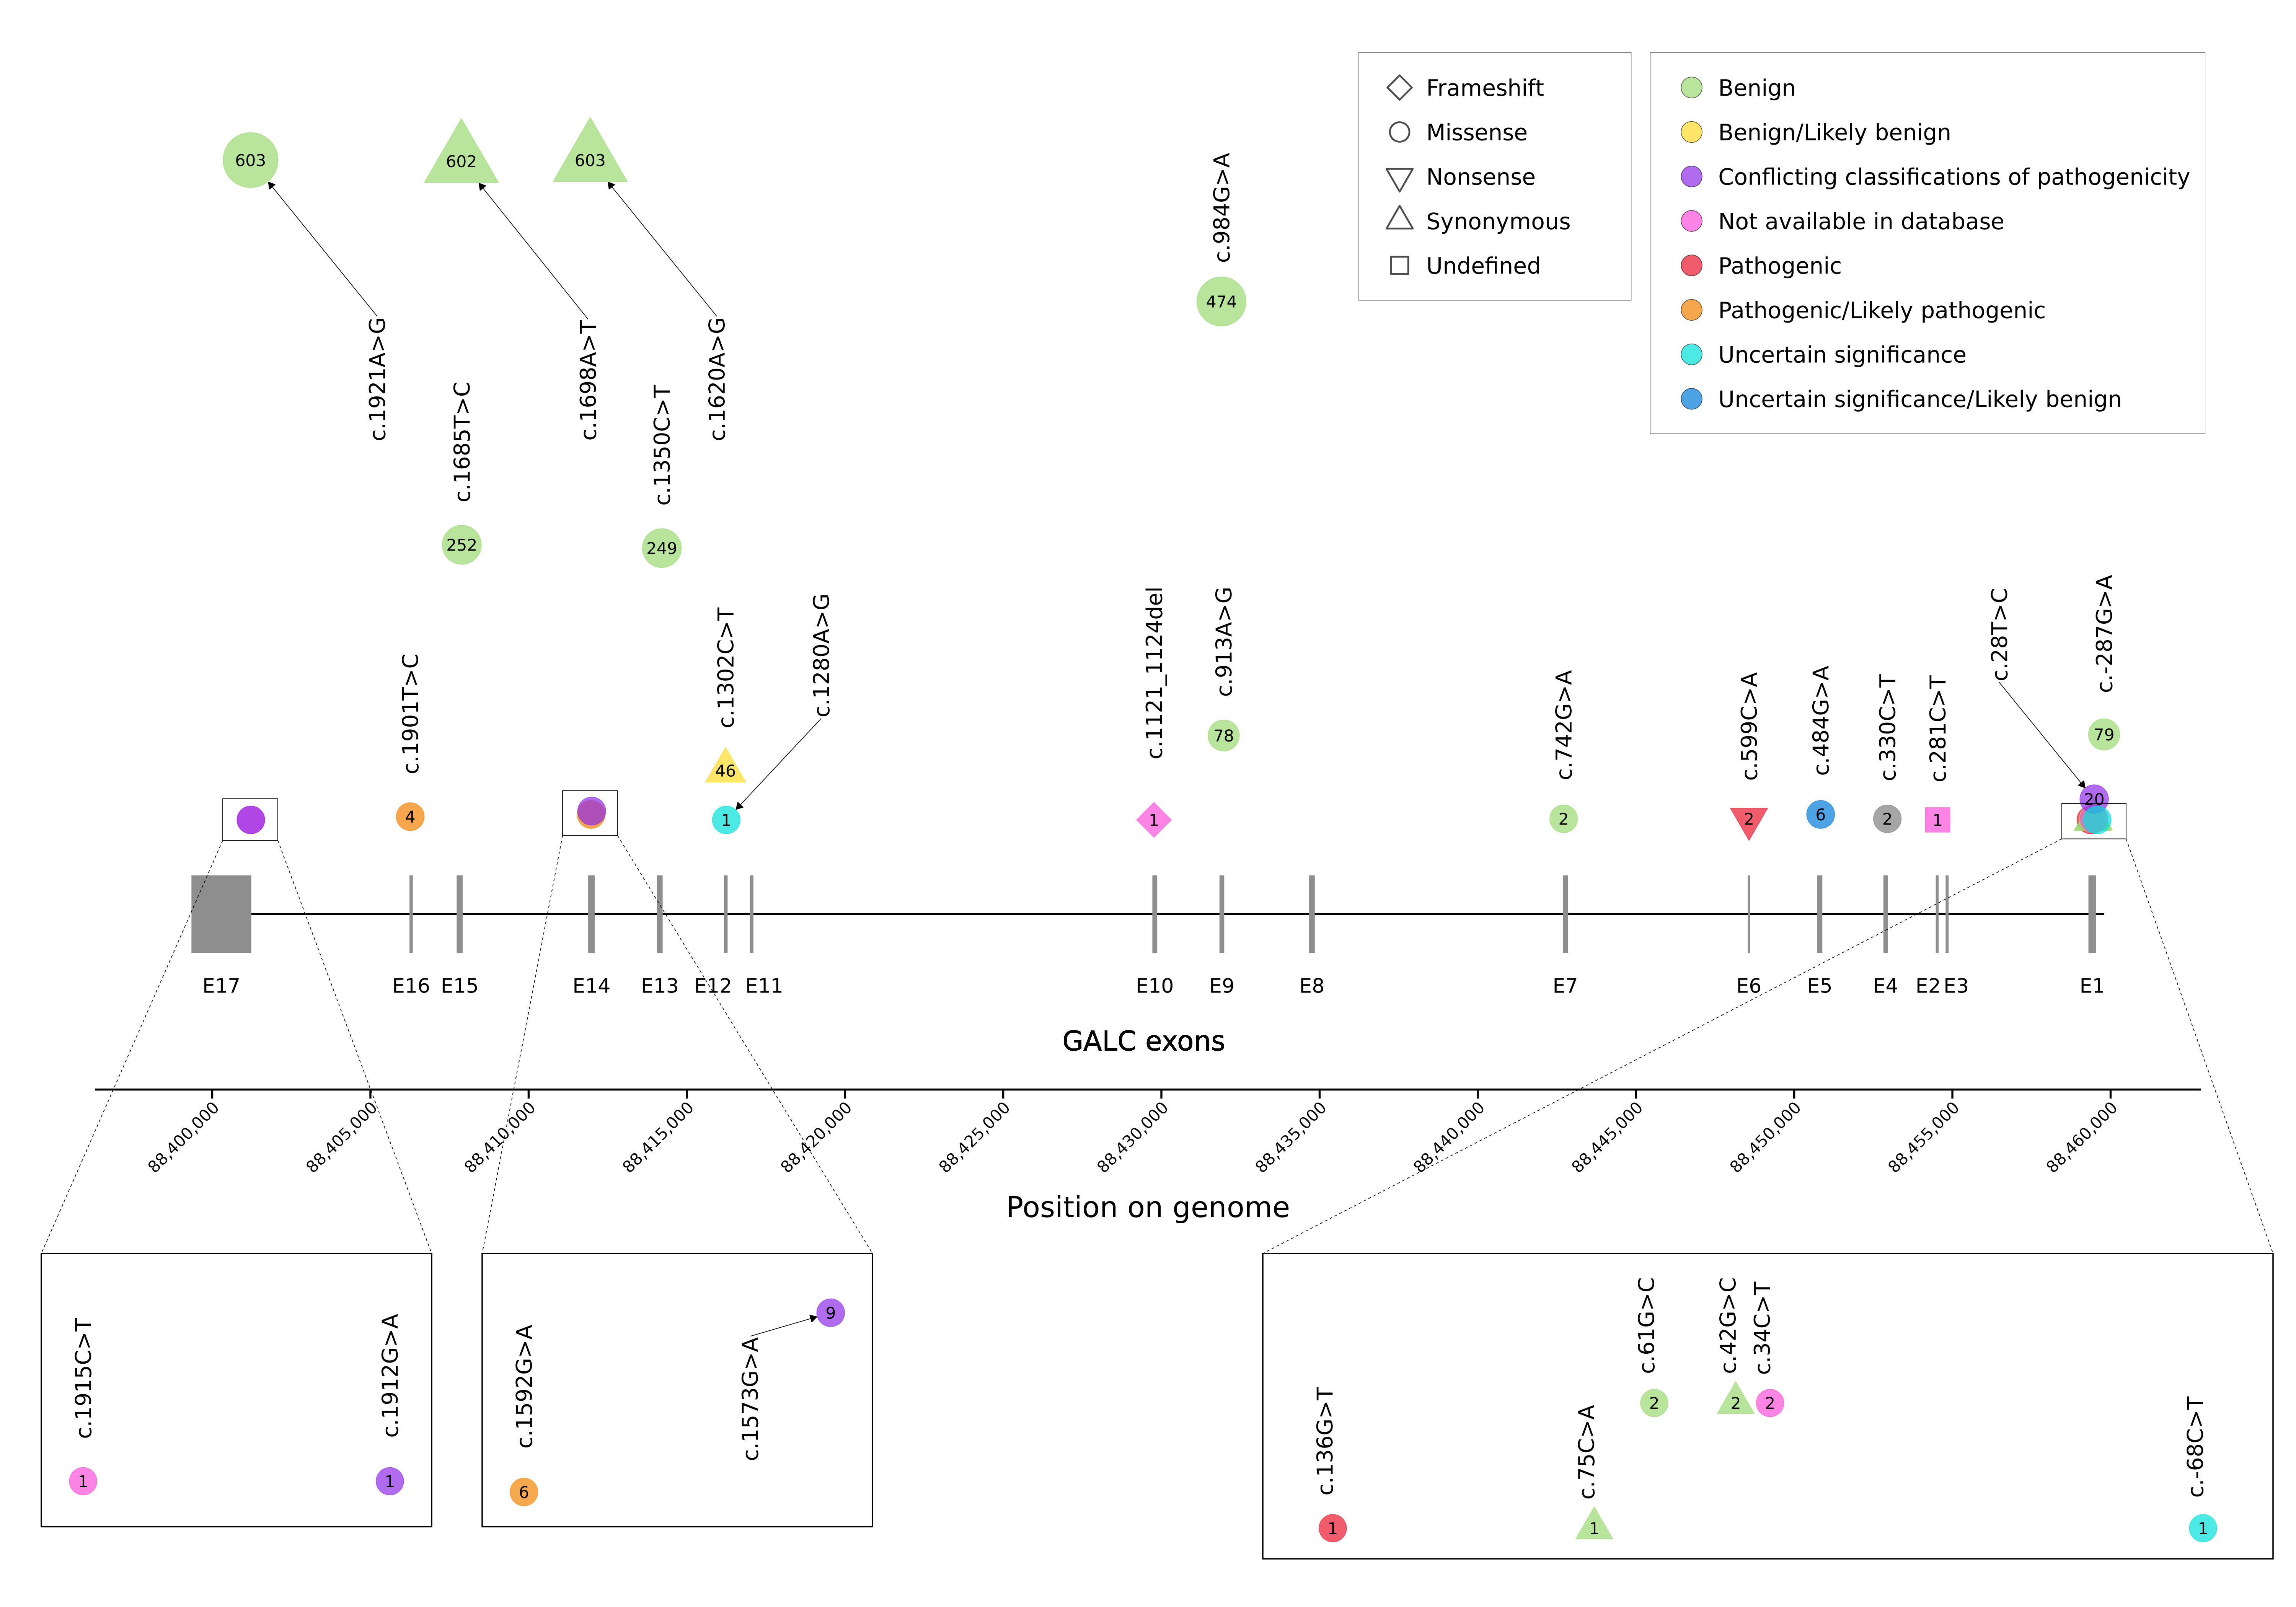

In [11]:
final_plot = ggdraw(

) + draw_plot(
    main_chart,
    x = 0.04,
    y = 0.23,
    width = 0.92,
    height = 0.77,
    scale = 1
) + draw_plot(
    subchart_1,
    x = 0.028, y = 0.06,
    width = 0.15, height = 0.13
) + geom_rect(
    aes(xmin = 0.028 - 0.01, xmax = 0.028 + 0.15 + 0.01, ymin = 0.06 - 0.01, ymax = 0.17 + 0.05),
    color = "black", fill = NA, size = 1
) + geom_rect(
    aes(xmin = 0.097, xmax = 0.121, ymin = 0.477, ymax = 0.503),
    color = "black", fill = NA, size = 0.5
) + geom_segment(
        aes(x=0.097, y=0.477, xend=0.028 - 0.01, yend=0.17 + 0.05), 
        color="#000000", 
        size=0.5,
        linetype = "dashed"
) + geom_segment(
        aes(x= 0.121, y=0.477, xend=0.028 + 0.15 + 0.01, yend=0.17 + 0.05), 
        color="#000000", 
        size=0.5,
        linetype = "dashed"
) + draw_plot( # ----------------------------------------------------------------------------
    subchart_3,
    x = 0.22, y = 0.06,
    width = 0.15, height = 0.17,
    scale = 1
) + geom_rect(
    aes(xmin = 0.22 - 0.01, xmax = 0.22 + 0.15 + 0.01, ymin = 0.06 - 0.01, ymax = 0.17 + 0.05),
    color = "black", fill = NA, size = 1
) + geom_rect(
    aes(xmin = 0.245, xmax = 0.269, ymin = 0.480, ymax = 0.508),
    color = "black", fill = NA, size = 0.5
) + geom_segment(
        aes(x=0.245, y=0.480, xend=0.22 - 0.01, yend=0.17 + 0.05), 
        color="#000000", 
        size=0.5,
        linetype = "dashed"
) + geom_segment(
        aes(x=0.269, y=0.480, xend=0.22 + 0.15 + 0.01, yend=0.17 + 0.05), 
        color="#000000", 
        size=0.5,
        linetype = "dashed"
) + draw_plot( # ----------------------------------------------------------------------------
    subchart_6,
    x = 0.56, y = 0.035,
    width = 0.42, height = 0.18,
    scale = 1
) + geom_rect(
    aes(xmin = 0.56 - 0.01, xmax = 0.56 + 0.42 + 0.01, ymin =  0.06 - 0.03, ymax = 0.17 + 0.05),
    color = "black", fill = NA, size = 1
) + geom_rect(
    aes(xmin = 0.898, xmax = 0.926, ymin = 0.478, ymax = 0.5),
    color = "black", fill = NA, size = 0.5
) + geom_segment(
        aes(x=0.898, y=0.478, xend=0.56 - 0.01, yend=0.17 + 0.05), 
        color="#000000", 
        size=0.5,
        linetype = "dashed"
) + geom_segment(
        aes(x=0.926, y=0.478, xend=0.56 + 0.42 + 0.01, yend=0.17 + 0.05), 
        color="#000000", 
        size=0.5,
        linetype = "dashed"
)

final_plot

In [13]:
ggsave(
    plot = final_plot, 
    file=file.path("target/", paste0("Krabe.pdf")), 
    width=50,
    height=35,
    limitsize = FALSE
)

ggsave(
    plot = final_plot, 
    file=file.path("target/", paste0("Krabe.png")), 
    width=50, 
    height=35,
    bg = "white",
    limitsize = FALSE
)

In [ ]:
print(warnings())